# Genre Classification from Lyrics: Word2Vec + Neural Network

Predicts a song's genre from its **lyrics only** (no metadata). The lyrics are cleaned, embedded with a Word2Vec model trained on the training lyrics, averaged into one vector per song and classified by a Keras neural network tuned with Hyperband.
The main metric is **macro F1**, because the genres are imbalanced. Seed 80085 is used everywhere, and everything that learns from data is fitted on the training split only.

**Contents:** 0. Setup · 1. Data · 2. Preprocessing · 3. Train/validation split · 4. Word2Vec song vectors · 5. Neural network · 6. Evaluation and submission

## 0. Setup

### Mount Google Drive
The data, checkpoints and custom code live on Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Install extra packages
Not preinstalled on Google Colab

In [ ]:
!pip install -q gensim keras-tuner contractions unidecode

### Imports

In [ ]:
import sys
from pathlib import Path

import numpy as np
import polars as pl

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import f1_score

In [ ]:
from gensim.models import Word2Vec, KeyedVectors

import nltk
for pkg in ["stopwords", "punkt", "punkt_tab", "wordnet"]:
    nltk.download(pkg, quiet=True)

In [ ]:
import keras
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, CSVLogger, ModelCheckpoint
import keras_tuner as kt

### Importing custom functions

In [ ]:
# folder that contains the utils package
sys.path.insert(0, '...')

from utils.pipeline_v2 import main_pipeline
from utils.funcs import song_vector, diagnose

### Paths
`data_dir` holds the original files, `w2v_dir` the checkpoints and results of this notebook.

In [ ]:
data_dir = Path('...')
w2v_dir = Path('...')

## 1. Data

### Load the data
`train.csv` has the genre (`tag`), `test.csv` does not.

In [ ]:
df_train = pl.read_csv(data_dir / 'train.csv')
df_test = pl.read_csv(data_dir / 'test.csv')

## 2. Preprocessing

### Remove duplicate songs
Lyrics sites often list the same song more than once (covers, remasters, re-uploads). If one copy lands in the training split and another in the validation split, the model is rewarded for memorising. Exact duplicates are therefore removed from the training data **before** cleaning and splitting.
The number of test lyrics also found in train is printed for reference only; test rows are never dropped.

In [ ]:
print("train rows before:", df_train.height)
print("duplicate lyrics in train:", df_train["lyrics"].is_duplicated().sum())
print("test lyrics also in train:", df_test["lyrics"].is_in(df_train["lyrics"].implode()).sum())

# keep the first copy of every song; the test set is left untouched because every id needs a prediction
df_train = df_train.unique(subset="lyrics", keep="first", maintain_order=True)
print("train rows after:", df_train.height)

train rows before: 134967
duplicate lyrics in train: 343
test lyrics also in train: 77
train rows after: 134789


### Split the training data into two halves
The training songs are cleaned in two stratified halves (same genre proportions) and joined again afterwards.

In [ ]:
# two stratified halves; they are concatenated again after cleaning
sample_df1, sample_df2 = train_test_split(
    df_train,
    train_size=0.5,
    stratify=df_train['tag'],
    random_state=80085
)

### Clean the lyrics
`main_pipeline` is applied to every song with `map_elements` and returns a list of tokens (`cleaned_lyrics`, type `pl.List(pl.String)`):
- **Cleaning:** removes section tags (e.g. *[Chorus]*), URLs, brackets and punctuation, and expands contractions.
- **Filtering:** discards non-alphabetic tokens, English stopwords and filler vocalisations (e.g. *oh*, *yeah*, *la*).
- **Standardising:** converts diacritics to ASCII, lowercases and lemmatises.

In [ ]:
# the same cleaning is applied to both halves of train and to test
def clean(df):
    return df.with_columns(
        pl.col("lyrics")
        .map_elements(lambda x: main_pipeline(x, tokenized_output=True),
                      return_dtype=pl.List(pl.String))
        .alias("cleaned_lyrics")
    )

cleaned_df_train = pl.concat([clean(sample_df1), clean(sample_df2)])
cleaned_df_test = clean(df_test)

### Remove songs with almost no lyrics (train only)
Songs with fewer than 10 tokens carry too little signal to learn from. This is applied to train only, because every test id needs a prediction.

In [ ]:
print("Before filtering - train rows:", cleaned_df_train.height)

# Filter out songs with fewer than 10 tokens
cleaned_df_train = cleaned_df_train.filter(pl.col("cleaned_lyrics").list.len() >= 10)

print("After filtering - train rows:", cleaned_df_train.height)

Before filtering - train rows: 134789
After filtering - train rows: 134582


### Save the cleaned data (one-off)
Parquet keeps the list-of-strings column intact and compresses well. Only `id`, `tag` (train) and `cleaned_lyrics` are stored, since no metadata is used. Rerun only if the preprocessing changes.

In [ ]:
# one-off checkpoint: rerun only if the preprocessing changes
cleaned_df_train.select(['id', 'tag', 'cleaned_lyrics']).write_parquet(w2v_dir / 'cleaned_train_df_tokenized.parquet')
cleaned_df_test.select(['id', 'cleaned_lyrics']).write_parquet(w2v_dir / 'cleaned_test_df_tokenized.parquet')

### Load the cleaned data (checkpoint)
Reloads the saved data, so a new session can start here without repeating the cleaning.

In [ ]:
cleaned_df_train = pl.read_parquet(w2v_dir / 'cleaned_train_df_tokenized.parquet')
cleaned_df_test = pl.read_parquet(w2v_dir / 'cleaned_test_df_tokenized.parquet')

### Genre distribution
Pop, rap and rock make up most of the songs. This imbalance is handled later with class weights and judged with macro F1.

In [ ]:
cleaned_df_train['tag'].value_counts()

tag,count
str,u32
"""country""",3461
"""rap""",38539
"""rock""",25282
"""pop""",55508
"""rb""",6191
"""misc""",5601


## 3. Train/validation split

### Split 75/25
The cleaned training songs are split 75/25, stratified by genre, so the validation set keeps the natural genre distribution. Everything that learns from data is fitted on `X_train` only.

In [ ]:
X = cleaned_df_train.select('id', 'cleaned_lyrics')
y = cleaned_df_train.select('tag')

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=80085, stratify=y
)

### Save the split ids
The song ids of both parts are saved to `splits.parquet` in `data_dir`, in the same row order as the feature files, so every model of the group can use exactly the same validation set.

In [ ]:
# which song went where, in the same row order as the feature files
pl.concat([
    X_train.select("id").with_columns(pl.lit("train").alias("split")),
    X_val.select("id").with_columns(pl.lit("val").alias("split")),
]).write_parquet(data_dir / "splits.parquet")

### Overlap check between splits
Checks that no validation song also appears in the training data (by id and by identical cleaned lyrics). The test count is for reference only; test rows are never dropped.

In [ ]:
train_text = X_train["cleaned_lyrics"].list.join(" ")
val_text = X_val["cleaned_lyrics"].list.join(" ")
test_text = cleaned_df_test["cleaned_lyrics"].list.join(" ")

print("val ids also in train:", X_val["id"].is_in(X_train["id"].implode()).sum())
print("val songs with identical cleaned lyrics in train:", val_text.is_in(train_text.implode()).sum())
print("test songs with identical cleaned lyrics in train+val:",
      test_text.is_in(pl.concat([train_text, val_text]).implode()).sum())

val ids also in train: 0
val songs with identical cleaned lyrics in train: 72
test songs with identical cleaned lyrics in train+val: 181


#### Result
No validation id appears in the training data. 72 validation songs (0.2% of 33,646) have cleaned lyrics identical to a training song, most likely covers or re-uploads whose raw text differed before cleaning. This share is too small to change the validation scores meaningfully, so they were kept.
181 test songs match a train or validation song; this is for reference only, and no test row is dropped or relabelled.

### Label format
The genre labels are flat 1D arrays of genre names (one per song, same row order as `X_train` / `X_val`).

In [ ]:
if isinstance(y_train, pl.DataFrame):   # safe to rerun: only converts once
    y_train = y_train["tag"].to_numpy()
    y_val = y_val["tag"].to_numpy()
print(y_train.shape, y_val.shape, sorted(set(y_train)))

(100936,) (33646,) ['country', 'misc', 'pop', 'rap', 'rb', 'rock']


---
# ▼ Word2Vec + Neural Network starts here ▼
---

**Everything above this cell (sections 0–3) follows the same steps as `preprocessing_unified.ipynb` and can be merged with it**: data loading, duplicate removal, cleaning, short-song filter, checkpoint and train/validation split. Differences to keep in mind when merging:
- This notebook uses `pipeline_v2`, the unified one `pipeline_v3`, and it keeps songs with at least 10 tokens (`>= 10`), the unified one more than 10 (`> 10`). The cleaned lyrics and the split change slightly after merging, so rerun everything below if the numbers must match exactly. The cached Word2Vec files are named after their parameters only, so delete them first, or the old vectors are loaded instead of retraining on the new data.
- The overlap check between splits (section 3) is not in the unified notebook and could be added there.
- The label-format cell turns `y_train` and `y_val` into NumPy arrays, while the unified notebook keeps them as Polars frames for the GloVe cells.
- Keep the model-specific imports in the setup cells (`gensim`, `keras`, `keras_tuner`, `StandardScaler`, `LabelEncoder`, `f1_score`, `song_vector`, `diagnose`).

**Only the sections below are specific to this model:** 4. Word2Vec song vectors · 5. Neural network · 6. Evaluation and submission.

## 4. Word2Vec song vectors

### Chosen Word2Vec configuration
Skip-gram with 300 dimensions, window 3, 2 negative samples and sample 1e-4; the other settings stay at their defaults.
Only `vector_size` gave a clear gain (+0.011 macro F1 on the logistic-regression probe); the other changes were within noise, so the faster settings were kept. The saved tuning results are shown below.

In [ ]:
pl.read_csv(w2v_dir / "word2vec_param_testing.csv").sort("macro_f1", descending=True)

shape: (14, 15)
┌─────────────────┬─────┬─────────────┬────────┬───────────┬──────────┬────────┬────────┬─────────┬───────┬────────────────┬──────────┬──────────┬─────────────┬─────────┐
│ changed         ┆ sg  ┆ vector_size ┆ window ┆ min_count ┆ negative ┆ epochs ┆ sample ┆ workers ┆ vocab ┆ zero_val_songs ┆ accuracy ┆ macro_f1 ┆ weighted_f1 ┆ seconds │
│ ---             ┆ --- ┆ ---         ┆ ---    ┆ ---       ┆ ---      ┆ ---    ┆ ---    ┆ ---     ┆ ---   ┆ ---            ┆ ---      ┆ ---      ┆ ---         ┆ ---     │
│ str             ┆ i64 ┆ i64         ┆ i64    ┆ i64       ┆ i64      ┆ i64    ┆ f64    ┆ i64     ┆ i64   ┆ i64            ┆ f64      ┆ f64      ┆ f64         ┆ i64     │
╞═════════════════╪═════╪═════════════╪════════╪═══════════╪══════════╪════════╪════════╪═════════╪═══════╪════════════════╪══════════╪══════════╪═════════════╪═════════╡
│ vector_size=300 ┆ 1   ┆ 300         ┆ 5      ┆ 5         ┆ 5        ┆ 5      ┆ 0.001  ┆ 3       ┆ 44448 ┆ 0              ┆ 0.47

### Train the final Word2Vec
Trained on `X_train` lyrics only, with 4 workers. Multi-threaded training makes the vectors differ slightly between runs, so the trained vectors are cached on Drive (the file name holds the parameters) and reused afterwards.

In [ ]:
w2v_params = dict(sg=1, vector_size=300, window=3, min_count=5, negative=2,
                  epochs=5, sample=1e-4, workers=4, seed=80085)

# the file name encodes the parameters, so a changed setting trains a new model
p = w2v_params
kv_path = w2v_dir / (f"w2v_sg{p['sg']}_d{p['vector_size']}_w{p['window']}_mc{p['min_count']}"
                     f"_n{p['negative']}_e{p['epochs']}_s{p['sample']}_wk{p['workers']}.kv")

train_sentences = X_train["cleaned_lyrics"].to_list()
print("longest song:", max(map(len, train_sentences)), "tokens (gensim ignores tokens beyond 10,000)")

if kv_path.exists():
    wv = KeyedVectors.load(str(kv_path))
else:
    wv = Word2Vec(sentences=train_sentences, **w2v_params).wv
    wv.save(str(kv_path))

vectors, index = wv.vectors, wv.key_to_index
print("vocabulary:", len(wv), "| vectors:", vectors.shape)

longest song: 8410 tokens (gensim ignores tokens beyond 10,000)
vocabulary: 44448 | vectors: (44448, 300)


### Sanity check of the embeddings
Nearest neighbours of a few words should be sensible. The search is limited to the 5,000 most frequent words, because otherwise rare tokens (typos, slang, names) dominate the lists.

In [ ]:
for w in ["love", "money", "gun"]:
    print(w, "->", wv.most_similar(w, topn=6, restrict_vocab=5000))

love -> [('want', 0.6203739047050476), ('baby', 0.6150416135787964), ('know', 0.6002540588378906), ('oh', 0.5693519711494446), ('girl', 0.5607079267501831), ('never', 0.5585854649543762)]
money -> [('cash', 0.6025311350822449), ('hunnids', 0.5796554684638977), ('guap', 0.5501501560211182), ('peso', 0.5346527695655823), ('dolla', 0.5207006931304932), ('bankroll', 0.5172616243362427)]
gun -> [('shotgun', 0.5520359873771667), ('tote', 0.5358376502990723), ('pistol', 0.5294862389564514), ('rifle', 0.5163490772247314), ('barrel', 0.5095669031143188), ('trigger', 0.5077905058860779)]


### Song vectors
Each song is the mean of its known word vectors. Songs with no known word get a zero vector, since test songs are never dropped. The vectors are saved to Drive, and the assertion checks that rows, labels and ids line up.

song_vector looks up the tokens that are in the vocabulary and takes the mean of their word vectors. The result is one 300-dimensional vector per song. If no token is known, it returns a zero vector. That is what happens to the 5 empty-lyric test songs.

In [ ]:
def embed(df):
    return np.vstack([song_vector(t, vectors, index) for t in df["cleaned_lyrics"].to_list()])

X_train_w2v, X_val_w2v, X_test_w2v = embed(X_train), embed(X_val), embed(cleaned_df_test)
test_ids = cleaned_df_test["id"]

assert len(y_train) == len(X_train_w2v) and len(y_val) == len(X_val_w2v) and len(test_ids) == len(X_test_w2v)

for name, M in [("train", X_train_w2v), ("val", X_val_w2v), ("test", X_test_w2v)]:
    print(f"{name}: {M.shape} | zero-vector songs: {int((~M.any(axis=1)).sum())}")

np.save(w2v_dir / "X_train_w2v.npy", X_train_w2v)
np.save(w2v_dir / "X_val_w2v.npy", X_val_w2v)
np.save(w2v_dir / "X_test_w2v.npy", X_test_w2v)

train: (100936, 300) | zero-vector songs: 0
val: (33646, 300) | zero-vector songs: 0
test: (33742, 300) | zero-vector songs: 5


### Statistics of the song vectors (before scaling)
Checks the training vectors for NaN, infinite and constant columns, and for skew, heavy tails and outliers. Also shows how much of val and test falls outside the training min-max range. This guides the choice of scaler.

In [ ]:
X = X_train_w2v
mean, std = X.mean(axis=0), X.std(axis=0)
z = (X - mean) / np.where(std == 0, 1, std)
skew = (z ** 3).mean(axis=0)
kurt = (z ** 4).mean(axis=0) - 3            # excess kurtosis (0 for a normal distribution)
lo, hi = X.min(axis=0), X.max(axis=0)

def spread(name, v):
    print(f"{name:<24} min {v.min():8.3f} | median {np.median(v):8.3f} | max {v.max():8.3f}")

print("NaN:", int(np.isnan(X).sum()), "| inf:", int(np.isinf(X).sum()), "| constant columns:", int((std == 0).sum()))
spread("column mean", mean)
spread("column std", std)
spread("column skewness", skew)
spread("column excess kurtosis", kurt)
print(f"values beyond 4 std: {(np.abs(z) > 4).mean():.4%} (a normal distribution gives about 0.006%)")

for name, M in [("val", X_val_w2v), ("test", X_test_w2v)]:
    print(f"{name}: values outside the train min-max range: {((M < lo) | (M > hi)).mean():.4%}")

NaN: 0 | inf: 0 | constant columns: 0
column mean              min   -0.278 | median   -0.001 | max    0.249
column std               min    0.031 | median    0.040 | max    0.058
column skewness          min   -2.685 | median   -0.016 | max    1.874
column excess kurtosis   min    0.414 | median    2.755 | max   29.040
values beyond 4 std: 0.2923% (a normal distribution gives about 0.006%)
val: values outside the train min-max range: 0.0021%
test: values outside the train min-max range: 0.0021%


### Check for songs without usable lyrics
Splits the zero-vector songs into empty lyrics and songs whose words are all outside the Word2Vec vocabulary. Train should have no songs under 10 tokens (filter); test is unfiltered.

In [ ]:
for name, df, M in [("train", X_train, X_train_w2v), ("val", X_val, X_val_w2v), ("test", cleaned_df_test, X_test_w2v)]:
    n_tokens = np.array([len(t) for t in df["cleaned_lyrics"].to_list()])
    empty, short = int((n_tokens == 0).sum()), int((n_tokens < 10).sum())
    zero = int((~M.any(axis=1)).sum())
    print(f"{name}: songs = {len(n_tokens)} | empty lyrics = {empty} | under 10 tokens = {short} | "
          f"zero vectors = {zero} (tokens but none known: {zero - empty})")

#### Result
Train (100,936 songs) and validation (33,646) contain no empty or short songs and no zero vectors.
Test (33,742 songs) keeps 5 empty-lyric songs, which get a zero vector, and 53 songs with under 10 tokens. All other test songs have at least one known word.

## 5. Neural network

### Z-score scaling of the song vectors
`StandardScaler` rewrites each dimension as (x - mean) / std. It is fitted on the training vectors only and then applied unchanged to validation and test, so nothing from those sets leaks into the preprocessing.

In [ ]:
scaler = StandardScaler().fit(X_train_w2v)
X_train_sc = scaler.transform(X_train_w2v)
X_val_sc   = scaler.transform(X_val_w2v)
X_test_sc  = scaler.transform(X_test_w2v)

# train should come out at mean 0 and std 1 per column; val and test only approximately
for name, M in [("train", X_train_sc), ("val", X_val_sc), ("test", X_test_sc)]:
    print(f"{name}: column means in [{M.mean(axis=0).min():.3f}, {M.mean(axis=0).max():.3f}] | "
          f"column stds in [{M.std(axis=0).min():.3f}, {M.std(axis=0).max():.3f}]")

train: column means in [-0.000, 0.000] | column stds in [1.000, 1.000]
val: column means in [-0.027, 0.022] | column stds in [0.945, 0.999]
test: column means in [-0.024, 0.021] | column stds in [0.950, 0.994]


### Genre labels as integers
`LabelEncoder` is fitted on the training labels only and maps each genre to an integer (alphabetical order). `le.classes_` gives the column order of the network's output probabilities, which `diagnose` and the submission use.

In [ ]:
le = LabelEncoder().fit(y_train)
y_train_int = le.transform(y_train)
y_val_int   = le.transform(y_val)

print(dict(zip(le.classes_, range(len(le.classes_)))))
print("train:", np.bincount(y_train_int), "| val:", np.bincount(y_val_int))

{np.str_('country'): 0, np.str_('misc'): 1, np.str_('pop'): 2, np.str_('rap'): 3, np.str_('rb'): 4, np.str_('rock'): 5}
train: [ 2596  4201 41631 28904  4643 18961] | val: [  865  1400 13877  9635  1548  6321]


### Class weights
Balanced weights (n_samples / (n_classes × class count), the same formula as scikit-learn's `balanced`) give the small genres more influence on the loss. They counter the imbalance and are simple to apply.

In [ ]:
counts = np.bincount(y_train_int)
class_weight_dict = {i: len(y_train_int) / (len(counts) * c) for i, c in enumerate(counts)}   # same formula as sklearn "balanced"

pl.DataFrame({"genre": le.classes_, "train_songs": counts,
              "weight": [round(class_weight_dict[i], 3) for i in range(len(counts))]})

genre,train_songs,weight
str,i64,f64
"""country""",2596,6.48
"""misc""",4201,4.004
"""pop""",41631,0.404
"""rap""",28904,0.582
"""rb""",4643,3.623
"""rock""",18961,0.887


### Neural network architecture
A Sequential dense network on the scaled 300-d song vectors: ReLU hidden layers with dropout, and a softmax output with one probability per genre (column order of `le.classes_`). Labels are integers, so the loss is sparse categorical crossentropy. The seed is fixed for reproducibility.

In [ ]:
keras.utils.set_random_seed(80085)

def build_model(n_features, n_classes, units=(256, 128), dropout=0.3, lr=1e-3):
    model = keras.Sequential([keras.Input(shape=(n_features,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu"))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(n_classes, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model = build_model(X_train_sc.shape[1], len(le.classes_))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        77,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,726 (432.52 KB)

 Trainable params: 110,726 (432.52 KB)

 Non-trainable params: 0 (0.00 B)

### Class-weighted validation set
Training uses class weights, so the validation loss gets the same weights (taken from the training class frequencies). Without this, `val_loss`, which drives both early stopping and the search, would mostly reflect pop, rap and rock. It would then disagree with the loss being optimised and with macro F1.

In [ ]:
sw_val = np.array([class_weight_dict[c] for c in y_val_int])
val_data = (X_val_sc, y_val_int, sw_val)

### Hyperband search
Hyperband trains many configurations for a few epochs and gives more epochs only to the best ones, so a wide space is searched cheaply.
- **Space:** 1-3 hidden layers (the input is one mean-pooled vector, so little depth is expected to help). Each layer has 64-512 units in powers of 2. Dropout is 0.2-0.5 against overfitting the small genres. The learning rate is 1e-4 to 1e-2 on a log scale, since it acts multiplicatively. L2 is left out to keep the space small, as dropout already regularises.
- **Settings:** `max_epochs=30` (enough for trials to separate), `factor=3` (each round keeps the best third), one iteration (the space is small), batch size 256 (fast on about 100k songs).
- **Objective:** weighted `val_loss`, matching the training loss. Every trial uses the class weights and an `EarlyStopping` with patience 3, short because trials are short.
- **Reproducibility:** seed 80085. Results are saved on Drive with `overwrite=False`, so the search resumes after a Colab disconnect.

In [ ]:
def hypermodel(hp):
    n_layers = hp.Int("n_layers", 1, 3)
    units = tuple(hp.Choice(f"units_{i}", [64, 128, 256, 512]) for i in range(n_layers))
    dropout = hp.Float("dropout", 0.2, 0.5, step=0.1)
    lr = hp.Float("lr", 1e-4, 1e-2, sampling="log")
    return build_model(X_train_sc.shape[1], len(le.classes_), units, dropout, lr)

tuner = kt.Hyperband(
    hypermodel, objective="val_loss", max_epochs=30, factor=3, hyperband_iterations=1,
    seed=80085, directory=str(w2v_dir), project_name="nn_hyperband", overwrite=False)

tuner.search(
    X_train_sc, y_train_int, validation_data=val_data, epochs=30, batch_size=256,
    class_weight=class_weight_dict,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3)], verbose=2)

Reloading Tuner from /content/drive/My Drive/Colab Notebooks/Text Mining/dataset/my_w2v_preprocessed/nn_hyperband/tuner0.json


### Hyperband results: best trials by macro F1
The search optimises `val_loss`, but the project metric is macro F1. The five best trials are re-scored with macro F1 on `X_val` (argmax of the predicted probabilities), and the final configuration is chosen from this table. The table is saved to Drive, so it can be shown after the search cell is commented out.

Repeated rows are the same configuration trained at different Hyperband epoch budgets.

In [ ]:
rows = []
for trial, m in zip(tuner.oracle.get_best_trials(5), tuner.get_best_models(5)):
    hps = trial.hyperparameters
    pred = m.predict(X_val_sc, batch_size=1024, verbose=0).argmax(axis=1)
    n = hps.get("n_layers")
    rows.append({"units": str([hps.get(f"units_{i}") for i in range(n)]),
                 "dropout": hps.get("dropout"), "lr": hps.get("lr"),
                 "val_loss": trial.score,
                 "val_macro_f1": f1_score(y_val_int, pred, average="macro")})

hyperband_results = pl.DataFrame(rows).sort("val_macro_f1", descending=True)
hyperband_results.write_csv(w2v_dir / "hyperband_top5.csv")
hyperband_results

units,dropout,lr,val_loss,val_macro_f1
str,f64,f64,f64,f64
"""[128, 256]""",0.3,0.000132,1.11291,0.409554
"""[512, 256, 256]""",0.3,0.000228,1.10874,0.407062
"""[512, 256, 256]""",0.3,0.000228,1.109545,0.406917
"""[64, 512, 64]""",0.3,0.00044,1.113251,0.401011
"""[64, 512, 64]""",0.3,0.00044,1.117744,0.398588


### Final fit with callbacks
The chosen configuration is retrained from scratch, because trials only ran up to 30 epochs with a short patience. It trains for at most 100 epochs, with early stopping ending it sooner. Batch size 256 and the class weights are as in the search. All callbacks monitor the weighted `val_loss`.
- **EarlyStopping:** patience 8, restoring the best epoch's weights.
- **ReduceLROnPlateau:** halves the learning rate after 3 epochs without improvement, down to 1e-6. The patience is below the early-stopping one, so the rate drops before training stops.
- **CSVLogger:** saves the per-epoch history for the learning curves.
- **ModelCheckpoint:** saves the best model to Drive, which protects against a Colab disconnect.

In [ ]:
best_units, best_dropout, best_lr = [128, 256], 0.3, 0.000132	   # best trial by macro F1 (hyperband_top5.csv)

keras.utils.set_random_seed(80085)
model = build_model(X_train_sc.shape[1], len(le.classes_), best_units, best_dropout, best_lr)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    CSVLogger(str(w2v_dir / "nn_training_log.csv")),
    ModelCheckpoint(str(w2v_dir / "best_nn.keras"), monitor="val_loss", save_best_only=True),
]

history = model.fit(
    X_train_sc, y_train_int, validation_data=val_data, epochs=100, batch_size=256,
    class_weight=class_weight_dict, callbacks=callbacks, verbose=2)
print("best epoch:", int(np.argmin(history.history["val_loss"])) + 1)

Epoch 1/100
395/395 - 8s - 20ms/step - accuracy: 0.3646 - loss: 1.5239 - val_accuracy: 0.4338 - val_loss: 1.2541 - learning_rate: 1.3200e-04
Epoch 2/100
395/395 - 4s - 9ms/step - accuracy: 0.4219 - loss: 1.3266 - val_accuracy: 0.4434 - val_loss: 1.2084 - learning_rate: 1.3200e-04
Epoch 3/100
395/395 - 5s - 12ms/step - accuracy: 0.4322 - loss: 1.2744 - val_accuracy: 0.4409 - val_loss: 1.1873 - learning_rate: 1.3200e-04
Epoch 4/100
395/395 - 5s - 12ms/step - accuracy: 0.4402 - loss: 1.2410 - val_accuracy: 0.4456 - val_loss: 1.1746 - learning_rate: 1.3200e-04
Epoch 5/100
395/395 - 4s - 9ms/step - accuracy: 0.4456 - loss: 1.2194 - val_accuracy: 0.4459 - val_loss: 1.1641 - learning_rate: 1.3200e-04
Epoch 6/100
395/395 - 4s - 9ms/step - accuracy: 0.4481 - loss: 1.2009 - val_accuracy: 0.4470 - val_loss: 1.1570 - learning_rate: 1.3200e-04
Epoch 7/100
395/395 - 5s - 14ms/step - accuracy: 0.4524 - loss: 1.1865 - val_accuracy: 0.4478 - val_loss: 1.1506 - learning_rate: 1.3200e-04
Epoch 8/100
395/

## 6. Evaluation and submission

### Performance on the validation set
The final network predicts genre probabilities for `X_val` (scaled, as in training). `diagnose` prints the accuracy and macro F1 against the majority-class guess, and draws the confusion matrix, per-genre scores, predicted against true genre shares, and the ROC curves.

val accuracy:   0.464  (always guessing the biggest genre: 0.412)
macro F1:       0.413
weighted F1:    0.455
              precision    recall  f1-score   support

     country       0.12      0.71      0.20       865
        misc       0.39      0.66      0.49      1400
         pop       0.69      0.13      0.23     13877
         rap       0.84      0.80      0.82      9635
          rb       0.17      0.60      0.26      1548
        rock       0.41      0.56      0.47      6321

    accuracy                           0.46     33646
   macro avg       0.44      0.58      0.41     33646
weighted avg       0.63      0.46      0.45     33646



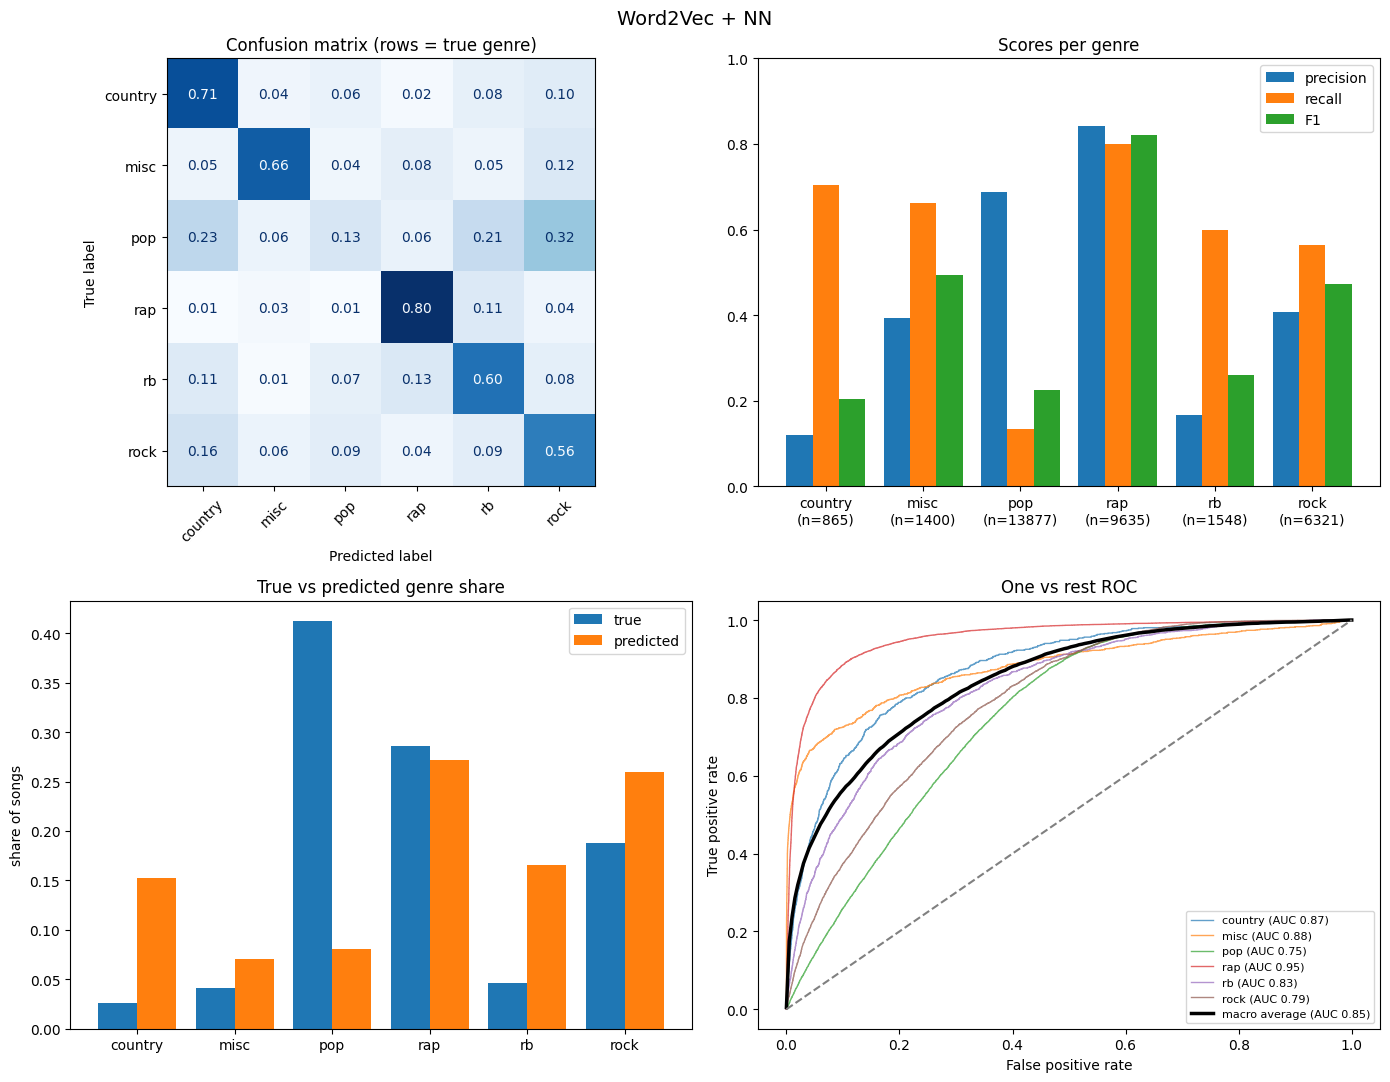

{'accuracy': 0.4637401176960114,
 'macro_f1': 0.4128928175018947,
 'weighted_f1': 0.4545752175442888}

In [ ]:
P_val = model.predict(X_val_sc, batch_size=1024, verbose=0)
diagnose(y_val, P_val, le.classes_, name="Word2Vec + NN")

### Test predictions and submission
The most likely genre (via `le.classes_`) is written as `id,tag`, and the ids are checked against the sample submission.

In [ ]:
P_test = model.predict(X_test_sc, batch_size=1024, verbose=0)
sub = pl.DataFrame({"id": test_ids, "tag": le.classes_[P_test.argmax(axis=1)]})

sample = pl.read_csv(data_dir / "sample_submission.csv")
assert sub.height == sample.height and set(sub["id"]) == set(sample["id"])
sub = sample.select("id").join(sub, on="id", how="left")   # same row order as the sample

sub.write_csv(w2v_dir / "submission_w2v_nn.csv")
sub["tag"].value_counts().sort("count", descending=True)

tag,count
str,u32
"""rap""",9279
"""rock""",8738
"""rb""",5425
"""country""",5192
"""pop""",2670
"""misc""",2438
